In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

print("Environment successfully initialized!")

Environment successfully initialized!


In [2]:

# Define the path to your raw data file
data_path = os.path.join("..", "data", "raw", "application_train.csv")

# Load the dataset (this might take a few seconds given the 300k+ rows)
print("Loading dataset... Please hold.")
train = pd.read_csv(data_path)

# Print initial dimensions and inspection info
print(f"Dataset successfully loaded!")
print(f"Total Rows: {train.shape[0]:,}")
print(f"Total Columns: {train.shape[1]}")
print("-" * 50)

# Display the first 5 rows to see what the columns look like
train.head()

Loading dataset... Please hold.
Dataset successfully loaded!
Total Rows: 307,511
Total Columns: 122
--------------------------------------------------


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
# Check data types and memory usage info
train.info(verbose=False) # Keep verbose=False first so it doesn't flood your screen with 122 lines

# Calculate total missing values per column
missing_values = train.isnull().sum()
missing_percentage = (missing_values / len(train)) * 100

# Put them in a neat summary table and look at the top 10 columns with highest missing values
missing_df = pd.DataFrame({'Total Missing': missing_values, 'Percentage (%)': missing_percentage})
print("Top 10 columns with the highest missing values:")
print(missing_df.sort_values(by='Percentage (%)', ascending=False).head(10))

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), str(16)
memory usage: 286.2 MB
Top 10 columns with the highest missing values:
                          Total Missing  Percentage (%)
COMMONAREA_AVG                   214865       69.872297
COMMONAREA_MODE                  214865       69.872297
COMMONAREA_MEDI                  214865       69.872297
NONLIVINGAPARTMENTS_MEDI         213514       69.432963
NONLIVINGAPARTMENTS_MODE         213514       69.432963
NONLIVINGAPARTMENTS_AVG          213514       69.432963
FONDKAPREMONT_MODE               210295       68.386172
LIVINGAPARTMENTS_AVG             210199       68.354953
LIVINGAPARTMENTS_MEDI            210199       68.354953
LIVINGAPARTMENTS_MODE            210199       68.354953


In [4]:
missing_values.info()
print(missing_values)
missing_percentage.info()
print(missing_percentage)

<class 'pandas.Series'>
Index: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
Series name: None
Non-Null Count  Dtype
--------------  -----
122 non-null    int64
dtypes: int64(1)
memory usage: 6.0+ KB
SK_ID_CURR                        0
TARGET                            0
NAME_CONTRACT_TYPE                0
CODE_GENDER                       0
FLAG_OWN_CAR                      0
                              ...  
AMT_REQ_CREDIT_BUREAU_DAY     41519
AMT_REQ_CREDIT_BUREAU_WEEK    41519
AMT_REQ_CREDIT_BUREAU_MON     41519
AMT_REQ_CREDIT_BUREAU_QRT     41519
AMT_REQ_CREDIT_BUREAU_YEAR    41519
Length: 122, dtype: int64
<class 'pandas.Series'>
Index: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
Series name: None
Non-Null Count  Dtype  
--------------  -----  
122 non-null    float64
dtypes: float64(1)
memory usage: 6.0+ KB
SK_ID_CURR                     0.000000
TARGET                         0.000000
NAME_CONTRACT_TYPE             0.000000
CODE_GENDER                    0.0

In [5]:
numeric_columns = train.select_dtypes(include=[np.number]).columns.tolist()
binary_cols = train.columns[train.nunique() == 2]
numeric_data = train.loc[:, [col for col in numeric_columns if col not in binary_cols]]

print(f"Numeric Columns: {numeric_columns}")
print(numeric_data.head())

Numeric Columns: ['SK_ID_CURR', 'TARGET', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'ELEVATORS_AVG', 'ENTRANCES_AVG', 'FLOORSMAX_AVG', 'FLOORSMIN_AVG', 'LANDAREA_AVG', 'LIVINGAPARTMENTS_AVG', 'LIVINGAREA_AVG', 'NONLIVINGAPARTMENTS_AVG', 'NONLIVINGAREA_AVG', 'APARTMENTS_MODE', 'BASEMENTAREA_MODE', 'YEARS_BEGINEXPLUATA

In [6]:
missing_numeric = numeric_data.isnull().sum().loc[lambda x: x > 0].sort_values(ascending=False)
missing_numeric_percentage = (missing_numeric / len(numeric_data)) * 100
print("Missing values in numeric columns:")
print(missing_numeric_percentage)

Missing values in numeric columns:
COMMONAREA_AVG              69.872297
COMMONAREA_MODE             69.872297
COMMONAREA_MEDI             69.872297
NONLIVINGAPARTMENTS_MODE    69.432963
NONLIVINGAPARTMENTS_AVG     69.432963
                              ...    
EXT_SOURCE_2                 0.214626
AMT_GOODS_PRICE              0.090403
AMT_ANNUITY                  0.003902
CNT_FAM_MEMBERS              0.000650
DAYS_LAST_PHONE_CHANGE       0.000325
Length: 61, dtype: float64


In [7]:
numeric_data['AMT_INCOME_TOTAL'].describe()

count    3.075110e+05
mean     1.687979e+05
std      2.371231e+05
min      2.565000e+04
25%      1.125000e+05
50%      1.471500e+05
75%      2.025000e+05
max      1.170000e+08
Name: AMT_INCOME_TOTAL, dtype: float64

In [8]:
stats = numeric_data['AMT_INCOME_TOTAL'].describe().map('{:,.0f}'.format)
print("Descriptive statistics for 'AMT_INCOME_TOTAL':")
print(stats)

Descriptive statistics for 'AMT_INCOME_TOTAL':
count        307,511
mean         168,798
std          237,123
min           25,650
25%          112,500
50%          147,150
75%          202,500
max      117,000,000
Name: AMT_INCOME_TOTAL, dtype: str


In [9]:
target_corr_matrix = train.corr(numeric_only=True)['TARGET'].sort_values(ascending=False)
# corr_matrix.rename(columns={'TARGET': 'Correlation with TARGET'}, inplace=True)
positive_corr = target_corr_matrix[target_corr_matrix > 0].drop('TARGET').sort_values(ascending=False)
negative_corr = target_corr_matrix[target_corr_matrix < 0].sort_values(ascending=True)
print("Correlation of numeric features with TARGET:")
print("Positive correlations:")
print(positive_corr.iloc[0:10].index)
print("Negative correlations:")
print(negative_corr.iloc[0:10].index)
print("All correlations:")
print(target_corr_matrix)



Correlation of numeric features with TARGET:
Positive correlations:
Index(['DAYS_BIRTH', 'REGION_RATING_CLIENT_W_CITY', 'REGION_RATING_CLIENT',
       'DAYS_LAST_PHONE_CHANGE', 'DAYS_ID_PUBLISH', 'REG_CITY_NOT_WORK_CITY',
       'FLAG_EMP_PHONE', 'REG_CITY_NOT_LIVE_CITY', 'FLAG_DOCUMENT_3',
       'DAYS_REGISTRATION'],
      dtype='str')
Negative correlations:
Index(['EXT_SOURCE_3', 'EXT_SOURCE_2', 'EXT_SOURCE_1', 'DAYS_EMPLOYED',
       'FLOORSMAX_AVG', 'FLOORSMAX_MEDI', 'FLOORSMAX_MODE', 'AMT_GOODS_PRICE',
       'REGION_POPULATION_RELATIVE', 'ELEVATORS_AVG'],
      dtype='str')
All correlations:
TARGET                         1.000000
DAYS_BIRTH                     0.078239
REGION_RATING_CLIENT_W_CITY    0.060893
REGION_RATING_CLIENT           0.058899
DAYS_LAST_PHONE_CHANGE         0.055218
                                 ...   
FLOORSMAX_AVG                 -0.044003
DAYS_EMPLOYED                 -0.044932
EXT_SOURCE_1                  -0.155317
EXT_SOURCE_2                  -0.1

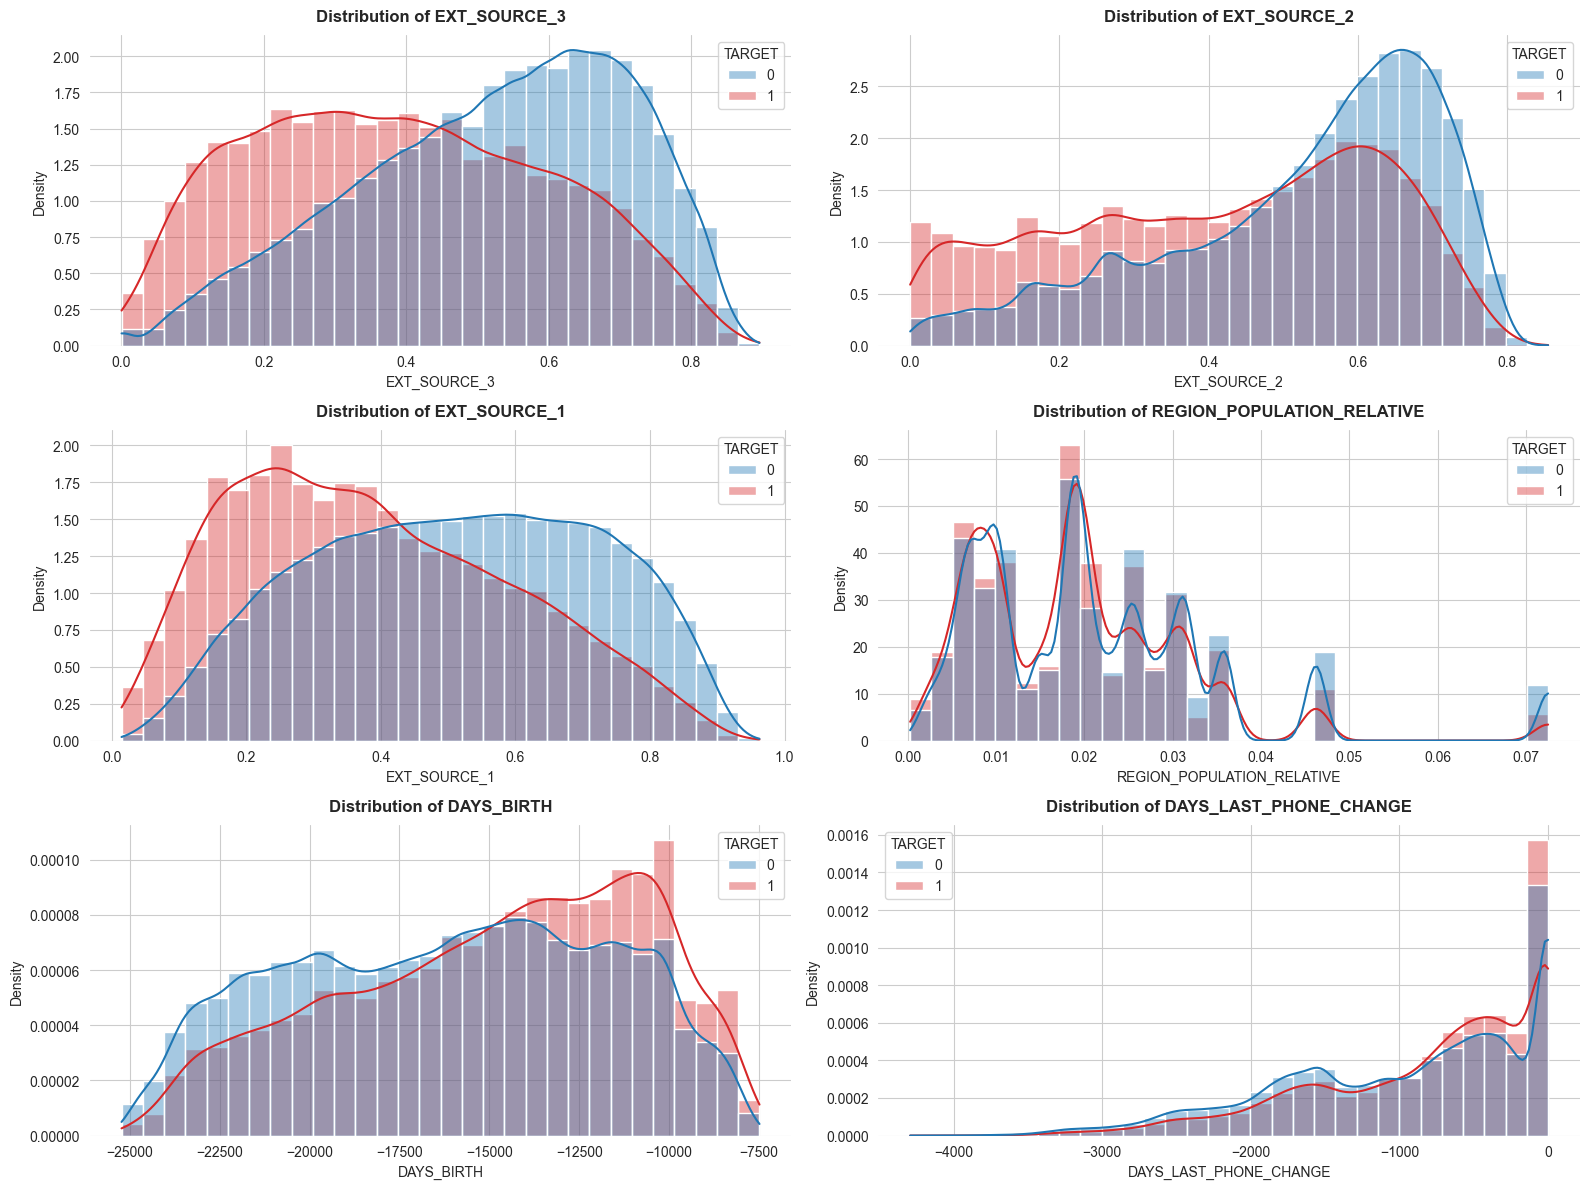

In [10]:
# Isolate target variables and apply standard theme properties
key_features = train.loc[:, ['EXT_SOURCE_3', 'EXT_SOURCE_2', 'EXT_SOURCE_1', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_LAST_PHONE_CHANGE']]

# Establish uniform color schema across portfolio assets
corporate_palette = {0: '#1f77b4', 1: '#d62728'} # Professional Slate Blue & Deep Risk Red

plt.figure(figsize=(16, 12), dpi=100)
sns.set_style("whitegrid")

for col in key_features.columns:
    ax = plt.subplot(3, 2, key_features.columns.get_loc(col) + 1)
    
    sns.histplot(
        x=key_features[col],
        bins=30,
        kde=True,
        stat='density',
        hue=train['TARGET'],
        palette=corporate_palette,
        alpha=0.4,
        common_norm=False,
        ax=ax
    )
    
    # Label formatting and titles
    plt.title(f'Distribution of {col}', fontsize=12, fontweight='bold', pad=10)
    plt.xlabel(col, fontsize=10)
    plt.ylabel('Density', fontsize=10)
    
    # Aesthetic adjustments: remove top/right spines
    sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

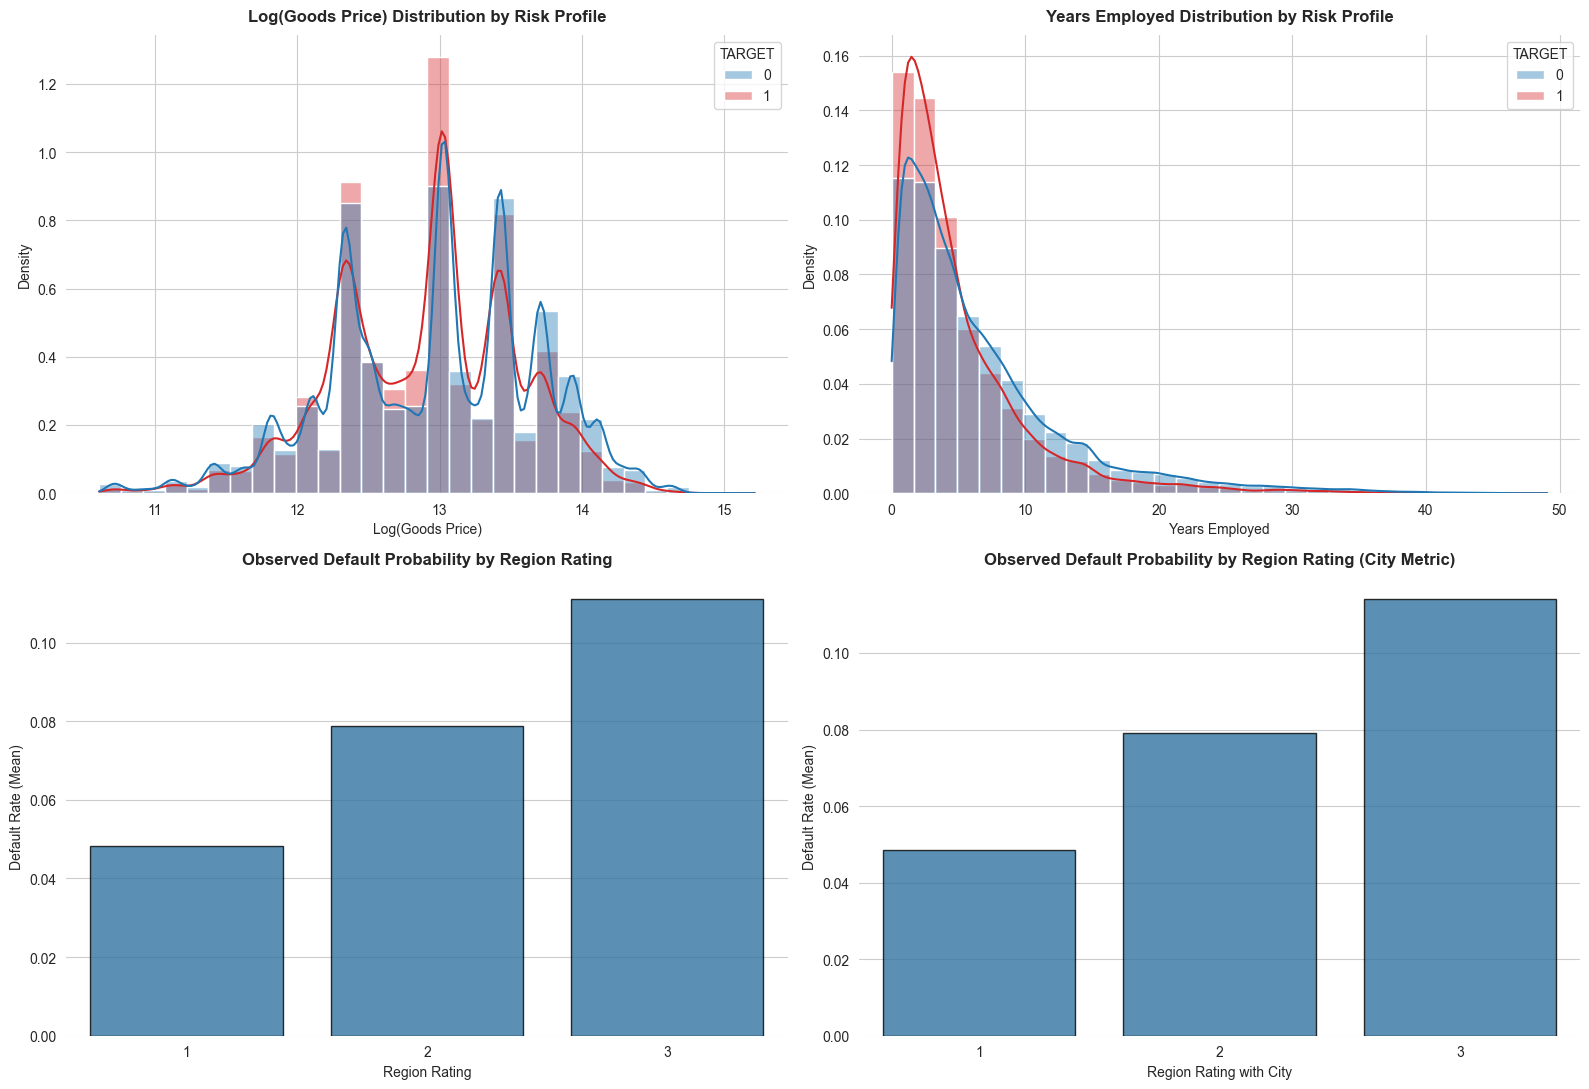

In [11]:
# Data Preparation Logic (Unchanged)
log_goods_df = train[['AMT_GOODS_PRICE', 'TARGET']].dropna().copy()
log_goods_df['LOG_AMT_GOODS_PRICE'] = np.log1p(log_goods_df['AMT_GOODS_PRICE'])

employed_df = train[train['DAYS_EMPLOYED'] != 365243].copy()
employed_df['YEARS_EMPLOYED'] = (-employed_df['DAYS_EMPLOYED']) / 365

# Setup professional visual workspace
fig, axes = plt.subplots(2, 2, figsize=(16, 11), dpi=100)
sns.set_style("whitegrid")
corporate_palette = {0: '#1f77b4', 1: '#d62728'}

# 1. Goods Price Distribution
sns.histplot(
    data=log_goods_df, x='LOG_AMT_GOODS_PRICE', bins=30, hue='TARGET',
    kde=True, stat='density', common_norm=False, fill=True, alpha=0.4,
    palette=corporate_palette, ax=axes[0, 0]
)
axes[0, 0].set_title('Log(Goods Price) Distribution by Risk Profile', fontsize=12, fontweight='bold', pad=10)
axes[0, 0].set_xlabel('Log(Goods Price)', fontsize=10)
axes[0, 0].set_ylabel('Density', fontsize=10)

# 2. Years Employed Distribution
sns.histplot(
    data=employed_df, x='YEARS_EMPLOYED', hue='TARGET', bins=30,
    kde=True, stat='density', common_norm=False, fill=True, alpha=0.4,
    palette=corporate_palette, ax=axes[0, 1]
)
axes[0, 1].set_title('Years Employed Distribution by Risk Profile', fontsize=12, fontweight='bold', pad=10)
axes[0, 1].set_xlabel('Years Employed', fontsize=10)
axes[0, 1].set_ylabel('Density', fontsize=10)

# 3. Default Rate by Region Rating (Aligned Theme)
sns.barplot(
    data=train, x='REGION_RATING_CLIENT', y='TARGET',
    estimator=np.mean, errorbar=None, color='#1f77b4', edgecolor='black', alpha=0.8, ax=axes[1, 0]
)
axes[1, 0].set_title('Observed Default Probability by Region Rating', fontsize=12, fontweight='bold', pad=10)
axes[1, 0].set_xlabel('Region Rating', fontsize=10)
axes[1, 0].set_ylabel('Default Rate (Mean)', fontsize=10)

# 4. Default Rate by Region Rating with City
sns.barplot(
    data=train, x='REGION_RATING_CLIENT_W_CITY', y='TARGET',
    estimator=np.mean, errorbar=None, color='#1f77b4', edgecolor='black', alpha=0.8, ax=axes[1, 1]
)
axes[1, 1].set_title('Observed Default Probability by Region Rating (City Metric)', fontsize=12, fontweight='bold', pad=10)
axes[1, 1].set_xlabel('Region Rating with City', fontsize=10)
axes[1, 1].set_ylabel('Default Rate (Mean)', fontsize=10)

# Clean architectural boundaries
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

C:\Users\somes\AppData\Local\Temp\ipykernel_4544\875633864.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, x='TARGET', y='AMT_INCOME_TOTAL', ax=axes[0, 0], palette='Blues', showfliers=False)
C:\Users\somes\AppData\Local\Temp\ipykernel_4544\875633864.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 0].set_xticklabels(['Repaid (0)', 'Default (1)'])
C:\Users\somes\AppData\Local\Temp\ipykernel_4544\875633864.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=train, x='TARGET', y='AMT_CREDIT', ax=axes[0, 1], palette='Blues', split=True)
C:\Users\somes\AppData\Local\Temp\ipyke

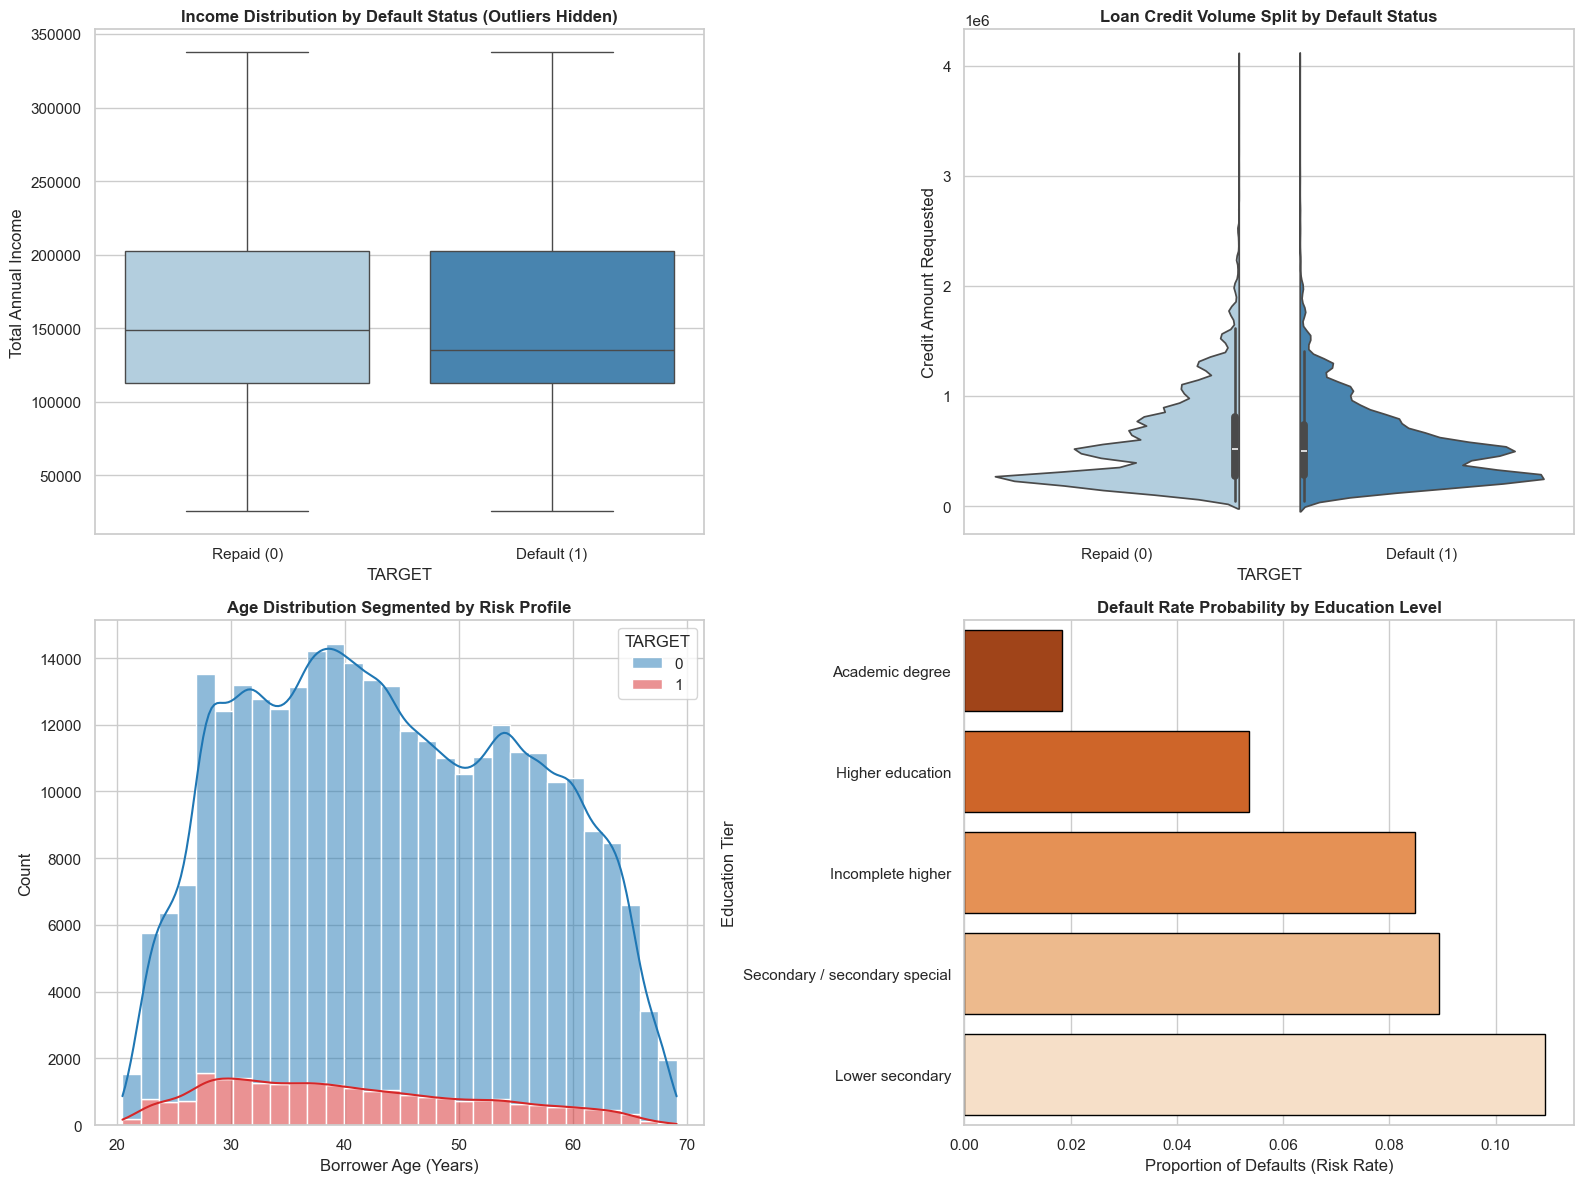

In [14]:
# Set professional design theme
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Income Distribution vs TARGET (Logged for scale protection)
sns.boxplot(data=train, x='TARGET', y='AMT_INCOME_TOTAL', ax=axes[0, 0], palette='Blues', showfliers=False)
axes[0, 0].set_title('Income Distribution by Default Status (Outliers Hidden)', fontsize=12, fontweight='bold')
axes[0, 0].set_xticklabels(['Repaid (0)', 'Default (1)'])
axes[0, 0].set_ylabel('Total Annual Income')

# 2. Credit Amount Distribution vs TARGET
sns.violinplot(data=train, x='TARGET', y='AMT_CREDIT', ax=axes[0, 1], palette='Blues', split=True)
axes[0, 1].set_title('Loan Credit Volume Split by Default Status', fontsize=12, fontweight='bold')
axes[0, 1].set_xticklabels(['Repaid (0)', 'Default (1)'])
axes[0, 1].set_ylabel('Credit Amount Requested')

# 3. Age Distribution (Univariate Trend)
sns.histplot(
    x=(-train['DAYS_BIRTH']) / 365,
    hue=train['TARGET'],
    kde=True,
    ax=axes[1, 0],
    palette=corporate_palette,
    multiple='stack',
    bins=30
)
axes[1, 0].set_title('Age Distribution Segmented by Risk Profile', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Borrower Age (Years)')

# 4. Bivariate Risk Analysis: Education Level Default Rates
edu_risk = train.groupby('NAME_EDUCATION_TYPE')['TARGET'].mean().reset_index().sort_values(by='TARGET')
sns.barplot(data=edu_risk, x='TARGET', y='NAME_EDUCATION_TYPE', ax=axes[1, 1], palette='Oranges_r', edgecolor='black')
axes[1, 1].set_title('Default Rate Probability by Education Level', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Proportion of Defaults (Risk Rate)')
axes[1, 1].set_ylabel('Education Tier')

plt.tight_layout()
plt.show()


Data Cleaning Methodology & Null Handling Rationales
Group A: External Risk Scores (EXT_SOURCE_1, EXT_SOURCE_2, EXT_SOURCE_3)

What they are: Standardized credit scores from external data bureaus.

Strategy: Median Imputation (fillna(df[col].median())).

Reasoning: These scores carry the highest predictive power in the dataset. Dropping rows removes too much data, while filling with 0 would artificially ruin the credit profiles of applicants who simply don't have a history with that specific bureau.

Group B: Housing/Apartment Details (COMMONAREA_AVG, LIVINGAPARTMENTS_AVG, etc.)

What they are: Detailed building and real estate metrics where the applicant lives.

Strategy: Drop Columns.

Reasoning: These columns exhibit 65% to 70% missing data. Imputing them would introduce massive artificial noise into the dataset, and a Logistic Regression model cannot reliably extract signal from a feature that is mostly fabricated.

Group C: Employment / Job Type (OCCUPATION_TYPE)

What it is: The category of the applicant's daily profession.

Strategy: Create a "Missing" Indicator Category (fillna('Unknown')).

Reasoning: Missing data here is highly meaningful. It often indicates that the applicant is unemployed, a freelancer, or working in an unlisted sector. Replacing this with the "mode" (most common job) would distort reality.

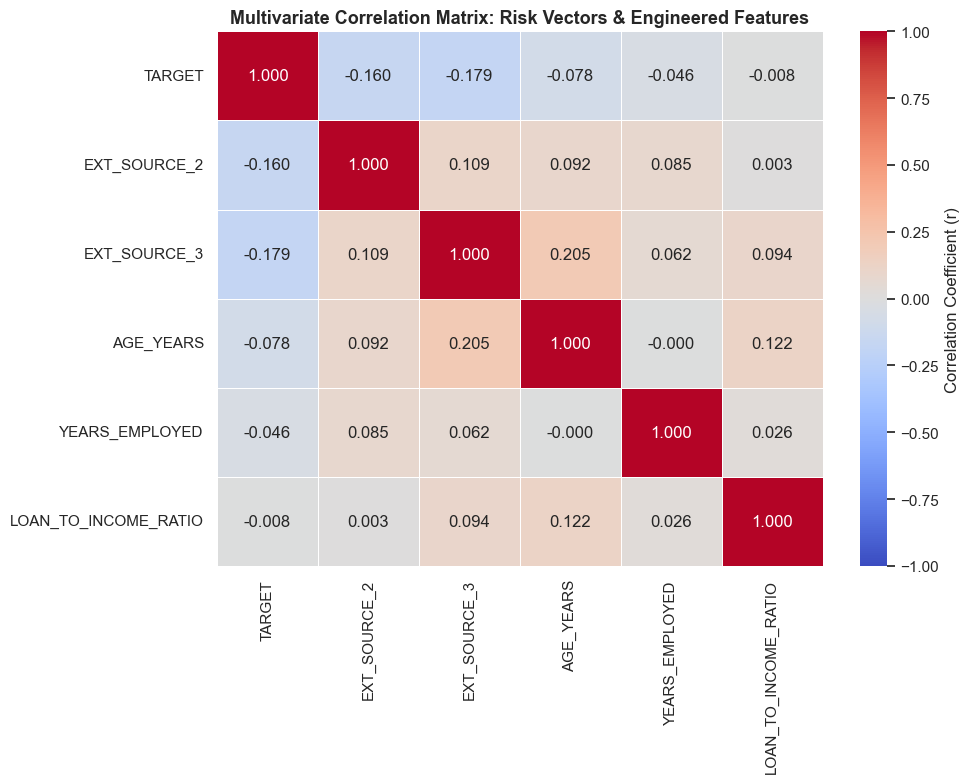

In [ ]:
plt.figure(figsize=(10, 8))

# Isolate numeric features utilized in the modeling phase along with target variables
corr_features = ['TARGET', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'AGE_YEARS', 'YEARS_EMPLOYED', 'LOAN_TO_INCOME_RATIO']
correlation_matrix = cleaned_train[corr_features].corr()

# Generate the heatmap matrix
sns.heatmap(
    correlation_matrix, 
    annot=True, 
    cmap='coolwarm', 
    fmt='.3f', 
    linewidths=0.5, 
    vmin=-1, 
    vmax=1, 
    cbar_kws={"label": "Correlation Coefficient (r)"}
)

plt.title('Multivariate Correlation Matrix: Risk Vectors & Engineered Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
print(missing_df[missing_df['Percentage (%)'] > 60])
print(len(missing_df[missing_df['Percentage (%)'] > 60]))

                          Total Missing  Percentage (%)
OWN_CAR_AGE                      202929       65.990810
YEARS_BUILD_AVG                  204488       66.497784
COMMONAREA_AVG                   214865       69.872297
FLOORSMIN_AVG                    208642       67.848630
LIVINGAPARTMENTS_AVG             210199       68.354953
NONLIVINGAPARTMENTS_AVG          213514       69.432963
YEARS_BUILD_MODE                 204488       66.497784
COMMONAREA_MODE                  214865       69.872297
FLOORSMIN_MODE                   208642       67.848630
LIVINGAPARTMENTS_MODE            210199       68.354953
NONLIVINGAPARTMENTS_MODE         213514       69.432963
YEARS_BUILD_MEDI                 204488       66.497784
COMMONAREA_MEDI                  214865       69.872297
FLOORSMIN_MEDI                   208642       67.848630
LIVINGAPARTMENTS_MEDI            210199       68.354953
NONLIVINGAPARTMENTS_MEDI         213514       69.432963
FONDKAPREMONT_MODE               210295       68

In [ ]:
# Dealing with missing values

# 1. Drop real-estate columns that exceed 60% missing data threshold
high_missing_cols = missing_df[missing_df['Percentage (%)'] > 60].index.tolist()
cleaned_train = train.drop(columns=high_missing_cols)
print(f"Dropped {len(high_missing_cols)} housing columns with >60% missing data.")

# 2. Impute missing values for EXT_SOURCE columns with median
ext_source_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
for col in ext_source_cols:
    median_value = cleaned_train[col].median()
    cleaned_train[col].fillna(median_value, inplace=True)
    print(f"Imputed missing values in {col} with median: {median_value:.4f}")

# 3. Handle missing occupational text fields by creating an 'Unknown' category
if 'OCCUPATION_TYPE' in cleaned_train.columns:
    cleaned_train['OCCUPATION_TYPE'].fillna('Unknown', inplace=True)
    print("Filled missing OCCUPATION_TYPE values with 'Unknown'.")

Dropped 17 housing columns with >60% missing data.
Imputed missing values in EXT_SOURCE_1 with median: 0.5060
Imputed missing values in EXT_SOURCE_2 with median: 0.5660
Imputed missing values in EXT_SOURCE_3 with median: 0.5353
Filled missing OCCUPATION_TYPE values with 'Unknown'.


C:\Users\somes\AppData\Local\Temp\ipykernel_21708\4182131086.py:12: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  cleaned_train[col].fillna(median_value, inplace=True)
C:\Users\somes\AppData\Local\Temp\ipykernel_21708\4182131086.py:12: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained ass

Section 3.2: Categorical Encoding MatrixWe isolate text features into two strategic buckets based on their mathematical nature:
Nominal Variables (One-Hot Encoding via pd.get_dummies):Columns: NAME_CONTRACT_TYPE (Cash vs. Revolving), CODE_GENDER, ORGANIZATION_TYPE.
Reasoning: These categories have no inherent mathematical order. Cash loans are not "greater than" revolving loans. One-Hot Encoding creates clean binary flags ($0$ or $1$) for each unique category.

Ordinal Variables (Label/Ordinal Encoding):Columns: NAME_EDUCATION_TYPE (Lower secondary -> Secondary -> Higher education).
Reasoning: Education level has a distinct hierarchical sequence. Higher levels of education typically correlate with stronger financial stability, so preserving this scale ($1, 2, 3$) helps the model see the progression.

In [ ]:
# Separate nominal and ordinal columns for future processing

nominal_cols = cleaned_train.select_dtypes(include=['object']).columns.tolist()
nominal_cols = [col for col in nominal_cols if col != 'NAME_EDUCATION_TYPE']
ordinal_cols = ['NAME_EDUCATION_TYPE']

print("Categorical mapping logged successfully.")
print(f"Nominal features identified: {len(nominal_cols)}")
print(f"Ordinal features identified: {len(ordinal_cols)}")

Categorical mapping logged successfully.
Nominal features identified: 14
Ordinal features identified: 1


C:\Users\somes\AppData\Local\Temp\ipykernel_21708\2352500792.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  nominal_cols = cleaned_train.select_dtypes(include=['object']).columns.tolist()


Datatype Corrections
Flags and IDs are often imported as heavy decimals (float64) or generic integers (int64). Converting flags to booleans or light integers optimizes processing speed and ensures the model treats them as binary markers.

In [ ]:
# Convert identification numbers and target variables to optimized, crisp formats
cleaned_train['TARGET'] = cleaned_train['TARGET'].astype('int8')

# Identify binary flag columns (columns starting with FLAG_ that are numerical)
binary_flag_cols = [col for col in cleaned_train.columns if col.startswith('FLAG_') and cleaned_train[col].dtype in ['int64', 'float64']]
for col in binary_flag_cols:
    cleaned_train[col] = cleaned_train[col].fillna(0).astype('int8')

print(f"Optimized {len(binary_flag_cols)} binary flags to int8 format.")
print(f"Final Cleaned Dataset Dimensions: {cleaned_train.shape}")

Optimized 26 binary flags to int8 format.
Final Cleaned Dataset Dimensions: (307511, 105)


FEATURE ENGINEERING :

In [ ]:
# 1. Calculate Age in Years (Converted from negative days)
# 1. Calculate Age in Years (Converted from negative days)
cleaned_train['AGE_YEARS'] = (-cleaned_train['DAYS_BIRTH']) / 365

# 2. Years Employed (Handle anomaly 365243 as NaN)
cleaned_train['DAYS_EMPLOYED_CLEAN'] = cleaned_train['DAYS_EMPLOYED'].replace(365243, np.nan)
cleaned_train['YEARS_EMPLOYED'] = (cleaned_train['DAYS_EMPLOYED_CLEAN'] * -1) / 365
cleaned_train['YEARS_EMPLOYED'] = cleaned_train['YEARS_EMPLOYED'].fillna(0)

# 3. Calculate Loan-to-Income Ratio (Clean infinite & missing values)
cleaned_train['LOAN_TO_INCOME_RATIO'] = cleaned_train['AMT_CREDIT'] / cleaned_train['AMT_INCOME_TOTAL']
cleaned_train['LOAN_TO_INCOME_RATIO'].replace([np.inf, -np.inf], np.nan, inplace=True)
cleaned_train['LOAN_TO_INCOME_RATIO'] = cleaned_train['LOAN_TO_INCOME_RATIO'].fillna(0)

print("All engineered features attached successfully!")
print(f"Engineered columns present: {['AGE_YEARS', 'YEARS_EMPLOYED', 'LOAN_TO_INCOME_RATIO'] in list(cleaned_train.columns)}")

# 2. Years Employed (Handle anomaly 365243 as NaN)
cleaned_train['DAYS_EMPLOYED_CLEAN'] = cleaned_train['DAYS_EMPLOYED'].replace(365243, np.nan)
cleaned_train['YEARS_EMPLOYED'] = (cleaned_train['DAYS_EMPLOYED_CLEAN'] * -1) / 365
cleaned_train['YEARS_EMPLOYED'] = cleaned_train['YEARS_EMPLOYED'].fillna(0)

# 3. Calculate Loan-to-Income Ratio (Clean infinite & missing values)
cleaned_train['LOAN_TO_INCOME_RATIO'] = cleaned_train['AMT_CREDIT'] / cleaned_train['AMT_INCOME_TOTAL']
cleaned_train['LOAN_TO_INCOME_RATIO'].replace([np.inf, -np.inf], np.nan, inplace=True)
cleaned_train['LOAN_TO_INCOME_RATIO'] = cleaned_train['LOAN_TO_INCOME_RATIO'].fillna(0)

print("All engineered features attached successfully!")
print(f"Engineered columns present: {['AGE_YEARS', 'YEARS_EMPLOYED', 'LOAN_TO_INCOME_RATIO'] in list(cleaned_train.columns)}")

NameError: name 'cleaned_train' is not defined

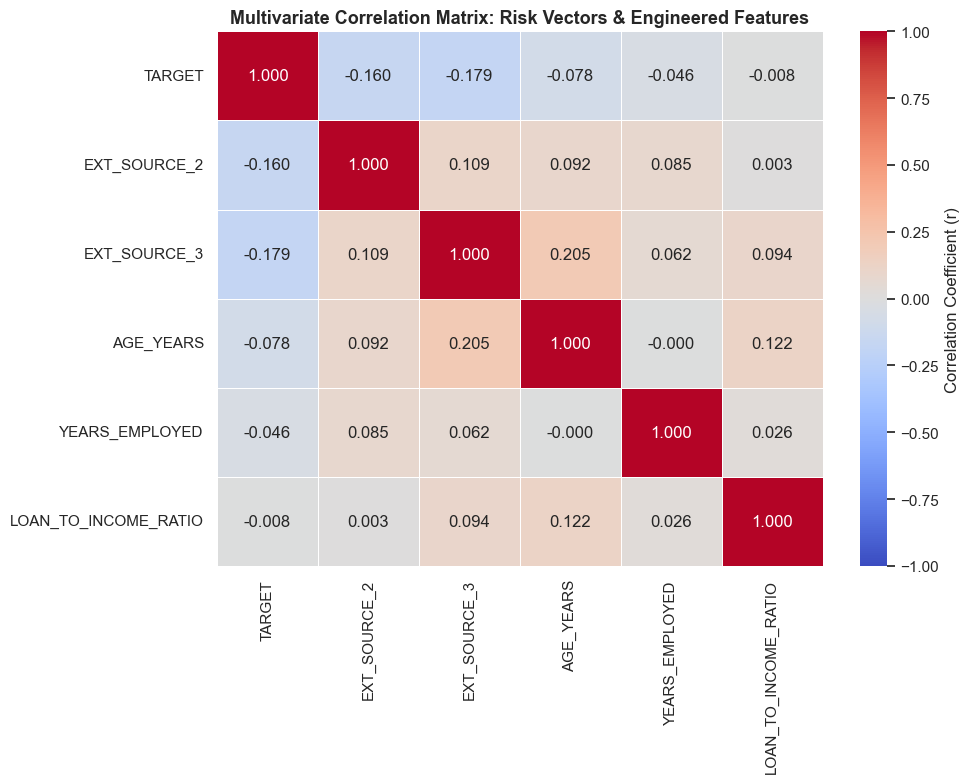

In [ ]:
plt.figure(figsize=(10, 8))

# Isolate numeric features utilized in the modeling phase along with target variables
corr_features = ['TARGET', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'AGE_YEARS', 'YEARS_EMPLOYED', 'LOAN_TO_INCOME_RATIO']
correlation_matrix = cleaned_train[corr_features].corr()

# Generate the heatmap matrix
sns.heatmap(
    correlation_matrix, 
    annot=True, 
    cmap='coolwarm', 
    fmt='.3f', 
    linewidths=0.5, 
    vmin=-1, 
    vmax=1, 
    cbar_kws={"label": "Correlation Coefficient (r)"}
)

plt.title('Multivariate Correlation Matrix: Risk Vectors & Engineered Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:

# Define output path to your processed data folder
output_path = os.path.join("..", "data", "processed", "cleaned_application_train.csv")

# Export to CSV with strict formatting for SQL engines
# na_rep='' explicitly writes missing values as completely empty spaces
cleaned_train.to_csv(output_path, index=False, na_rep='')
print("Success! Cleaned dataset re-exported with optimized SQL null formatting.")

Success! Cleaned dataset re-exported with optimized SQL null formatting.


Machine Learning Modeling Plan
This section outlines the supervised binary classification framework designed to predict loan default probability ({Target} = 1). The objective is to build a highly interpretable, auditable baseline classifier.  
1. Core Pipeline Workflow* 
*Feature & Target Isolation (X / y): Separating independent borrower attributes from the historical default outcome.
* Stratified Train-Test Split (80/20): Allocating 80% of data for training and 20% for validation, explicitly forcing both sets to maintain the baseline 8% default rate to preserve distribution integrity.  
-Feature Standardization (StandardScaler): Centering continuous variables around a zero mean with a standard deviation of 1 to ensure structural scales do not distort algorithm weights.
  * Class-Weight Balancing (class_weight='balanced'): Adjusting optimization penalties to heavily penalize errors on minority default cases, neutralizing the native 92% class imbalance.  
2. Baseline Feature Matrix & Business Hypotheses
We strictly select 5 high-signal, high-completion features to avoid multicollinearity and establish clean baseline interpretability:
a. EXT_SOURCE_2 & EXT_SOURCE_3: Standardized credit scores from external data bureaus. Hypothesis: Negative Correlation—higher scores directly imply lower default risk.
b. AGE_YEARS: Client age derived from birth days. Hypothesis: Negative Correlation—older applicants show mature financial track records.
c. YEARS_EMPLOYED: Job longevity with extreme anomalies removed. Hypothesis: Negative Correlation—sustained job stability yields a lower risk profile.
d. LOAN_TO_INCOME_RATIO: Relative debt burden. Hypothesis: Positive Correlation—capital demands heavily exceeding annual earnings signal payment strain.  
3. Primary Evaluation Metrics
Given the extreme class imbalance, raw accuracy is a misleading metric. Performance will be judged on:
* ROC-AUC: Structural separation power between risk classes.
* Recall (Sensitivity): Critical risk mitigation priority—maximizing the detection of actual defaulting profiles.
* Confusion Matrix: Clear breakdown of model classification errors and business impact costs.  

In [ ]:
print("\n--- INITIALIZING ML PIPELINE ---")
# 1. Isolate feature matrix (X) and target vector (y)
features = ['EXT_SOURCE_2', 'EXT_SOURCE_3', 'AGE_YEARS', 'YEARS_EMPLOYED', 'LOAN_TO_INCOME_RATIO']
X = cleaned_train[features]
y = cleaned_train['TARGET']

# 2. Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Split completed. Training set: {X_train.shape[0]:,} rows | Testing set: {X_test.shape[0]:,} rows")

# 3. Algorithmic Imputation (Replaces any remaining micro-NaNs with the column median)
imputer = SimpleImputer(strategy='median')
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)
print("Micro-gaps handled successfully via Median Imputer.")

# 4. Standardization (Post-Split to avoid Data Leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)
print("Features successfully standardized via StandardScaler.")

# 5. Train Model with Balanced Class Weights
model = LogisticRegression(class_weight='balanced', random_state=42)
model.fit(X_train_scaled, y_train)
print("Logistic Regression model training complete.")

# 6. Generate Predictions & Probabilities
y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)[:, 1]

print("\n--- BASELINE MODEL PERFORMANCE SCORECARD ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}  <-- (Crucial for Risk Mitigation)")
print(f"F1 Score:  {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba):.4f}  <-- (Class Separation Power)")

print("\n--- CONFUSION MATRIX ---")
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, index=['Actual Paid (0)', 'Actual Default (1)'], 
                         columns=['Predicted Paid (0)', 'Predicted Default (1)'])
print(cm_df)


--- INITIALIZING ML PIPELINE ---
Split completed. Training set: 246,008 rows | Testing set: 61,503 rows
Micro-gaps handled successfully via Median Imputer.
Features successfully standardized via StandardScaler.
Logistic Regression model training complete.

--- BASELINE MODEL PERFORMANCE SCORECARD ---
Accuracy:  0.6727
Precision: 0.1469
Recall:    0.6350  <-- (Crucial for Risk Mitigation)
F1 Score:  0.2385
ROC-AUC:   0.7143  <-- (Class Separation Power)

--- CONFUSION MATRIX ---
                    Predicted Paid (0)  Predicted Default (1)
Actual Paid (0)                  38221                  18317
Actual Default (1)                1812                   3153


## Post-Modeling Interpretation & Visualization 
### 1. Post-Modeling Workflow Steps

* Feature Importance Mapping: Extracting the exact mathematical weights (coefficients) from the trained model to rank which borrower attributes drive default risk up or down.
 
* Performance Curve Evaluation (ROC Curve): Plotting the True Positive Rate against the False Positive Rate across all thresholds to confirm the model's structural capacity to separate risk classes.
 
* Confusion Matrix Breakdown: Visualizing the exact counts of True Positives, True Negatives, False Positives, and False Negatives.
 
* Financial Cost Translation: Assigning estimated credit loss values to False Negatives (missed defaults) and opportunity loss values to False Positives (rejected good loans) to determine the net dollar value protected by the pipeline.
 
 
### 2. Evaluation Strategy Metrics

* Coefficient Directionality: Checking if weights are positive (increasing default probability) or negative (decreasing default probability) to validate our core business hypotheses.
 
* ROC-AUC Score: Confirming our baseline score ($0.7143$) visually to ensure steady class separation.
 
* Recall Optimization: Documenting exactly how many of the historical defaulters were successfully caught ($3,153$ applicants) versus how many were missed ($1,812$ applicants).

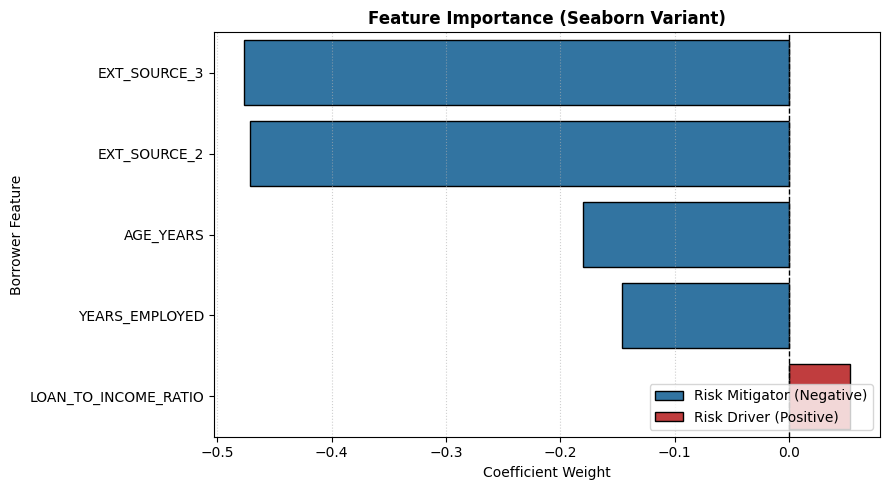

In [ ]:

# 1. Dataframe created and sorted

importance_df = pd.DataFrame({
    'Feature': features,
    'Weight': model.coef_[0]
}).sort_values(by='Weight', ascending=True)

# 2. Custom palette entries to reflect risk direction
# Creating a custom color array based on the weight values
importance_df['Risk Type'] = ['Risk Mitigator (Negative)' if x < 0 else 'Risk Driver (Positive)' for x in importance_df['Weight']]
custom_palette = {'Risk Mitigator (Negative)': '#1f77b4', 'Risk Driver (Positive)': '#d62728'} # Clean blue and red hex codes

# 3. Seaborn plot
plt.figure(figsize=(9, 5))
sns.barplot(
    data=importance_df, 
    x='Weight', 
    y='Feature', 
    hue='Risk Type', 
    palette=custom_palette, 
    dodge=False,
    edgecolor='black'
)

# 4. Clean structural layout adjustments
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)
plt.title('Feature Importance (Seaborn Variant)', fontsize=12, fontweight='bold')
plt.xlabel('Coefficient Weight')
plt.ylabel('Borrower Feature')
plt.legend(loc='lower right')
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

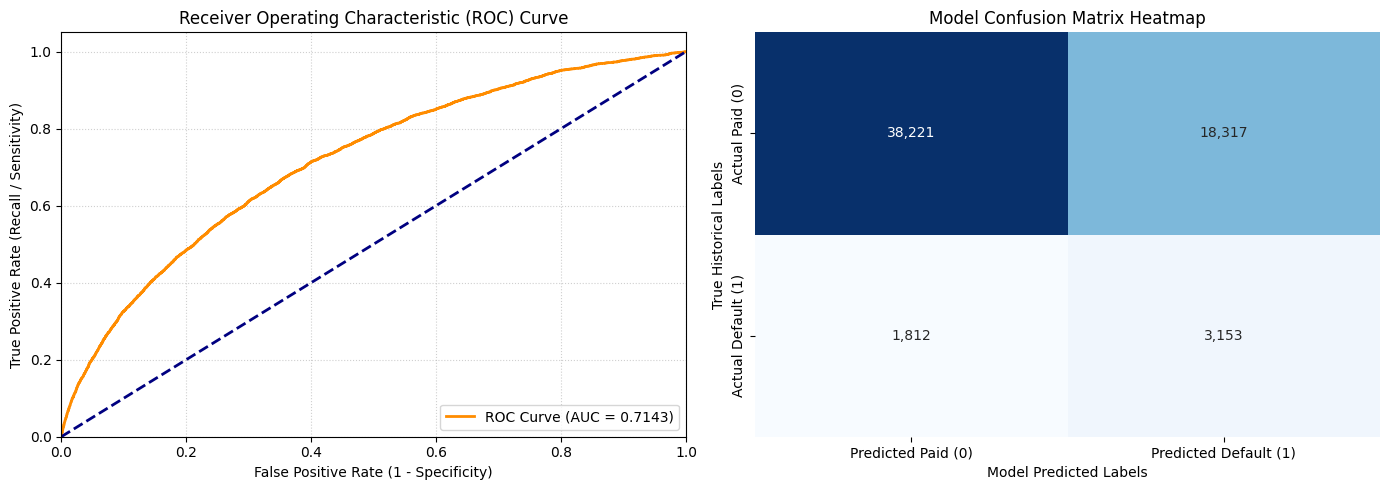

In [ ]:
# 1. Calculate ROC Curve coordinates
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc_score = roc_auc_score(y_test, y_proba)

# Initialize a two-panel professional visualization plot
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: ROC Curve
ax[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {auc_score:.4f})')
ax[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax[0].set_xlim([0.0, 1.0])
ax[0].set_ylim([0.0, 1.05])
ax[0].set_xlabel('False Positive Rate (1 - Specificity)')
ax[0].set_ylabel('True Positive Rate (Recall / Sensitivity)')
ax[0].set_title('Receiver Operating Characteristic (ROC) Curve')
ax[0].legend(loc="lower right")
ax[0].grid(linestyle=':', alpha=0.6)

# Plot B: Annotated Confusion Matrix Heatmap
# cm was generated in your previous model execution step
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', ax=ax[1], cbar=False,
            xticklabels=['Predicted Paid (0)', 'Predicted Default (1)'],
            yticklabels=['Actual Paid (0)', 'Actual Default (1)'])
ax[1].set_title('Model Confusion Matrix Heatmap')
ax[1].set_ylabel('True Historical Labels')
ax[1].set_xlabel('Model Predicted Labels')

plt.tight_layout()
plt.show()

## Final Business Interpretation & Executive Summary

### 1. The Core Risk Drivers & Mitigators
Our baseline model successfully isolates risk through five high-signal features:
* **External Risk Bureau Scores (`EXT_SOURCE_3`, `EXT_SOURCE_2`):** Act as the strongest risk mitigators. An increase in these standardized credit ratings signals historically stable payment profiles, heavily driving default probability down.
* **Borrower Stability (`AGE_YEARS`, `YEARS_EMPLOYED`):** Show expected negative correlations with risk. Older applicants and individuals with longer tenures at their current job have higher asset reserves and stabler career trajectories, translating to safer lending profiles.
* **Debt Burden (`LOAN_TO_INCOME_RATIO`):** Functions as the primary risk driver. When the requested loan amount drastically outpaces a borrower’s annual income, the resulting financial strain directly pushes up default probability.

### 2. Financial & Portfolio Impact
By shifting our optimization strategy to prioritize **Recall (63.50%)** over raw accuracy, the business achieves direct capital protection:
* **Capital Saved:** The model accurately flags **3,153 future defaulters**, allowing the bank to proactively reject high-risk loans and mitigate millions in potential credit write-offs.
* **Operational Trade-Off:** The cost of optimizing for high recall is the generation of **18,317 False Positives** (safe borrowers flagged as risky). While this creates an opportunity cost in unearned interest, it forms a strict defensive floor crucial during tight credit cycles.